# Monthly means and degree-day thresholds

Secondary analysis of NOAA 1991–2020 monthly normals. Run in this folder. Python execution outputs were captured directly; no Jupyter execution engine was used.

The preserved station files are in web/data/noaa-monthly-1991-2020 in this checkout. Script checks their SHA-256 hashes. Data grain: station-month; purposive selection of 24 airport stations. Values are °F and °F-days, base65°F. No contractor demand, energy-use or causal advertising claims.

Sources and qualifications: source-record.json and README.md.


In [1]:
from pathlib import Path
import sys, json
sys.path.insert(0, str(Path.cwd()))
from analysis import analyze, mean_proxy, month_days
from decimal import Decimal
rows, report = analyze()
print(json.dumps({k: report[k] for k in ['rawHashesMatched','stationMonths','variableValues','bothPublishedDirectionsPositive','bothDirectionsAtLeast10FDays','roundedNonzeroValues','contributingYearRange','stationMonthsWithMatchingYearCounts']}, indent=2))


{
  "rawHashesMatched": 24,
  "stationMonths": 288,
  "variableValues": 864,
  "bothPublishedDirectionsPositive": 221,
  "bothDirectionsAtLeast10FDays": 109,
  "roundedNonzeroValues": 13,
  "contributingYearRange": [
    22,
    29
  ],
  "stationMonthsWithMatchingYearCounts": 288
}


In [2]:
for r in report['focalExamples']:
    print(r['city'], r['month'], 'mean', r['temperature_F'], 'published', r['heating_F_days'], r['cooling_F_days'], 'proxy', r['proxy_heating_F_days'], r['proxy_cooling_F_days'])
print('February mean length:', month_days(2))


Tampa 12 mean 64.9 published 104.8 101.7 proxy 3.1 0.0
Denver 9 mean 64.8 published 105.3 99.2 proxy 6.0 0.0
Chicago 9 mean 66.3 published 77.2 116.1 proxy 0.0 39.0
Phoenix 11 mean 65.1 published 85.0 88.1 proxy 0.0 3.0
February mean length: 28.26666666666666666666666667


In [3]:
# Invented illustration, not an observed NOAA daily series.
temperatures = [Decimal(50), Decimal(80)]
heating = sum(max(Decimal(65)-t, Decimal(0)) for t in temperatures)
cooling = sum(max(t-Decimal(65), Decimal(0)) for t in temperatures)
mean = sum(temperatures)/2
assert (heating,cooling,mean)==(15,15,65)
print('Invented two-day mean:',mean,'F; heating:',heating,'F-days; cooling:',cooling,'F-days')


Invented two-day mean: 65 F; heating: 15 F-days; cooling: 15 F-days


Exported figure.png and figure.svg; identical focal values from the audited source.


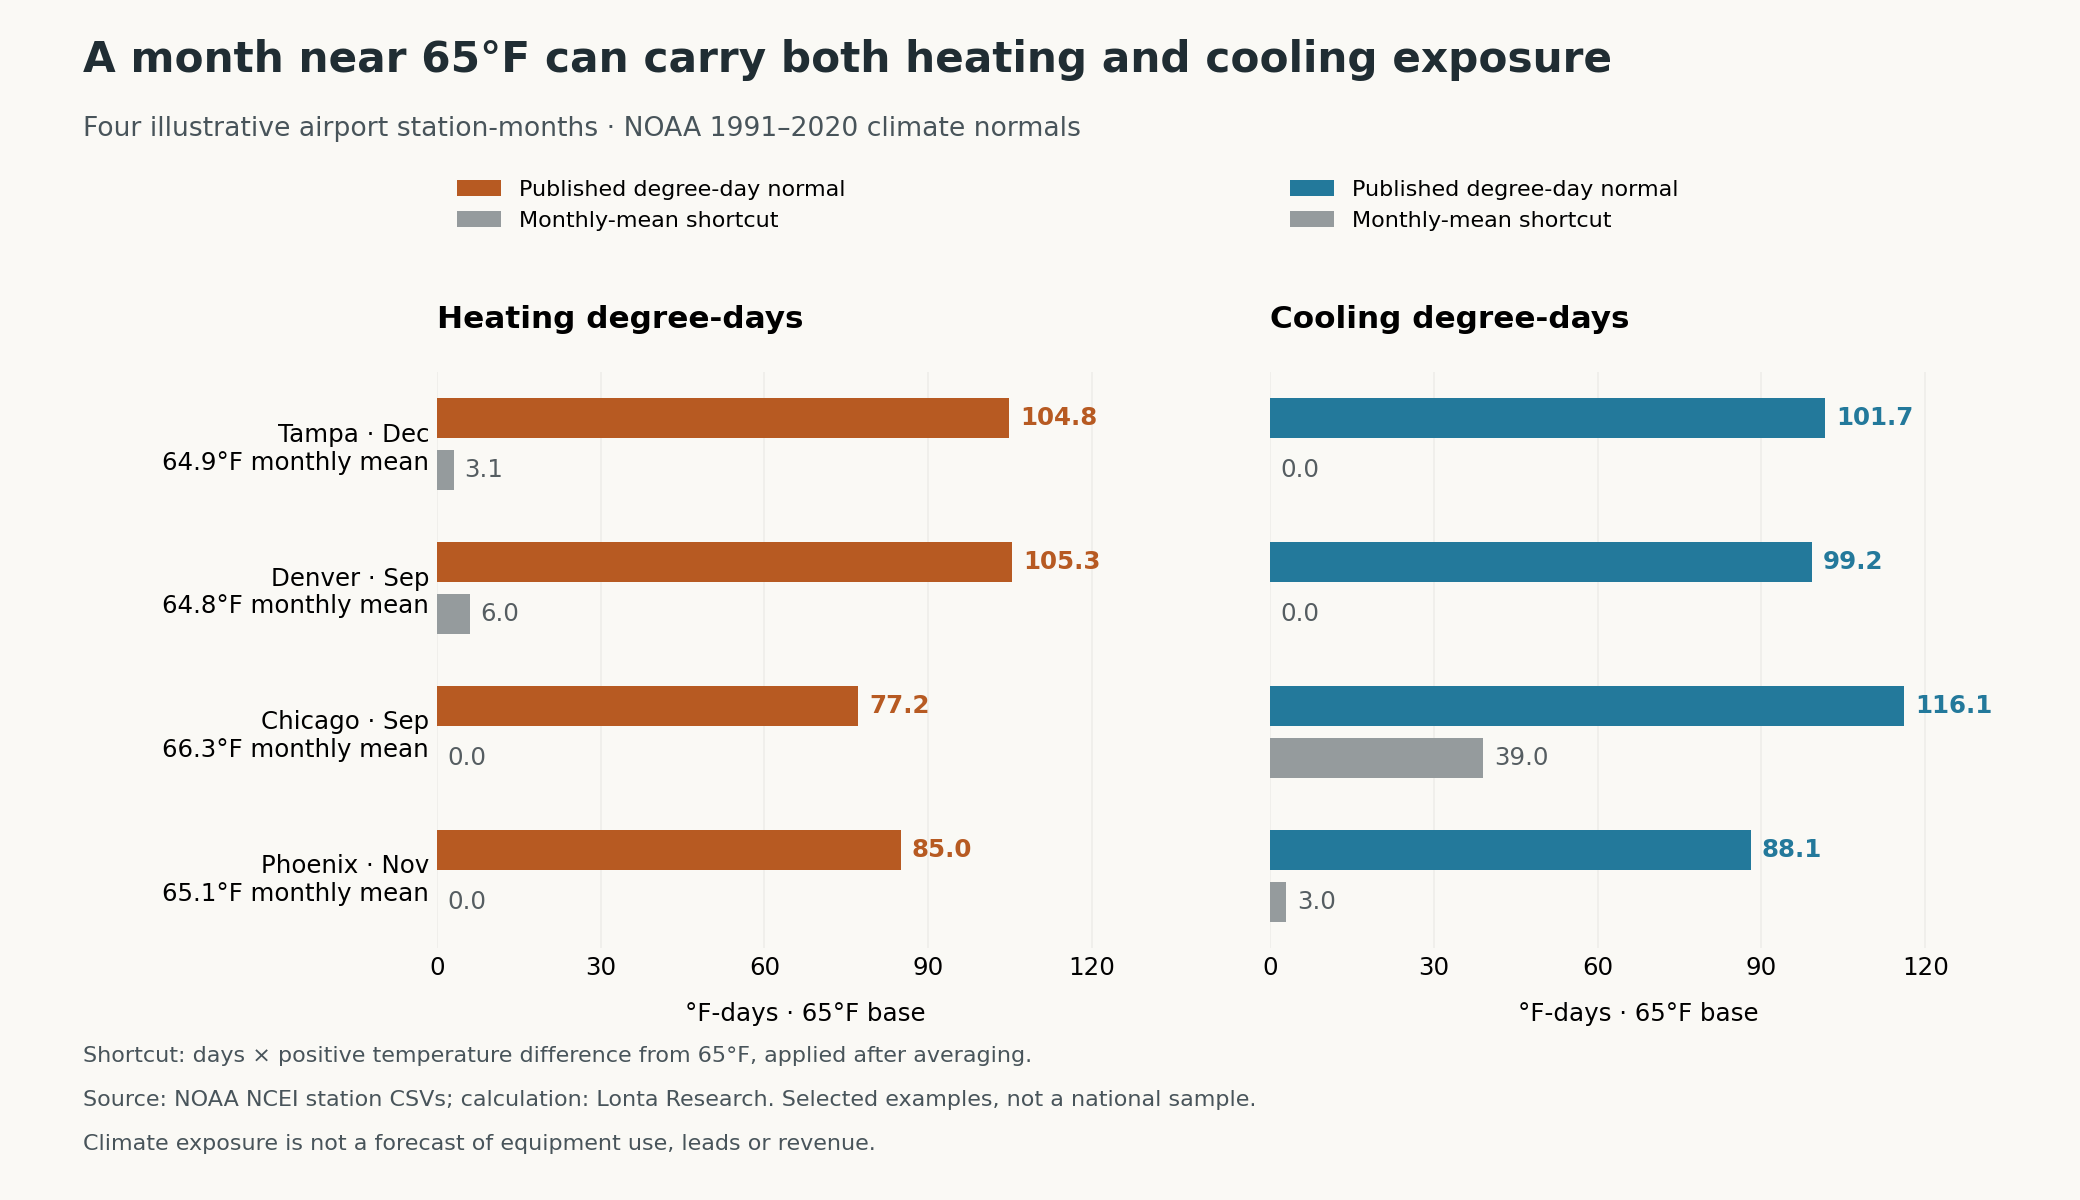

In [4]:
from analysis import chart
chart(report['focalExamples'])
print('Exported figure.png and figure.svg; identical focal values from the audited source.')


## Limits

These are climate normals, not current forecasts. Published normals use adjusted temperature records and estimation. Matching year counts do not prove identical daily records. Both directions in a monthly normal do not establish simultaneous use in any day, year or building. The four examples are selected illustrations. X flags preserve nonzero values rounded to zero. The arithmetic contrasts methods rather than estimating lost jobs.
